# Mean-reversion strategy: evaluation

This notebook asks one question: **is a mean-reversion strategy worth submitting on this data?**

1. Check whether the returns show any reversion at a horizon we can actually trade (positions earn their first return two days after the signal).
2. Define a simple reversion strategy.
3. Evaluate it with `evaluation.py`, across parameters and sub-periods.
4. Compare it with the trend model from the Quickstart.
5. Confirm the code works on synthetic prices that *do* revert, and that it has no look-ahead.
6. Test reversion at a much longer horizon (80 to 300 days), where the short-horizon strategy cannot see it.
7. Plot the combined model (trend plus gated long-horizon reversal) through the history.

Everything is driven by `PRICES_FILE` in the first cell, so the whole notebook can be re-run on the real data set.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.colors import LinearSegmentedColormap

notebook_file = globals().get("__vsc_ipynb_file__")
NOTEBOOK_DIR = Path(notebook_file).resolve().parent if notebook_file else Path.cwd()
sys.path.insert(0, str(NOTEBOOK_DIR))

from evaluation import calc_key_figures, plot_key_figures

DATE = "AsOfDate"
PRICES_FILE = "example_prices.csv"  # swap for the real data set

prices = pl.read_csv(NOTEBOOK_DIR / PRICES_FILE, try_parse_dates=True).rename({"dates": DATE})
instruments = [c for c in prices.columns if c != DATE]
ret = prices.select(DATE, pl.col(instruments).diff())

# plot styling
BLUE, RED, INK, MUTED, GRID = "#2a78d6", "#e34948", "#0b0b0b", "#8a8984", "#e4e3df"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID, "axes.grid": True,
    "grid.color": GRID, "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.labelcolor": INK, "axes.titlelocation": "left", "axes.titlesize": 11, "lines.linewidth": 2,
})
pl.Config.set_fmt_str_lengths(60)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_rows(40)
print(f"{prices.height} days, {prices[DATE].min()} to {prices[DATE].max()}, instruments: {instruments}")

5956 days, 2000-01-03 to 2023-01-11, instruments: ['diamonds', 'butter', 'cars', 'cucumber', 'bananas']


## 1. Is there any reversion to trade?

Returns are first normalised by a rolling volatility estimate, as in the modeling example, so that all instruments are on the same scale.

**Autocorrelation by lag.** A negative autocorrelation at lag $k$ means that a move today tends to be partly undone $k$ days later. A position decided on day $t$ earns its first return on day $t+2$, so **lag 1 cannot be traded**. Reversion has to show up at lag 2 or later to be of any use.

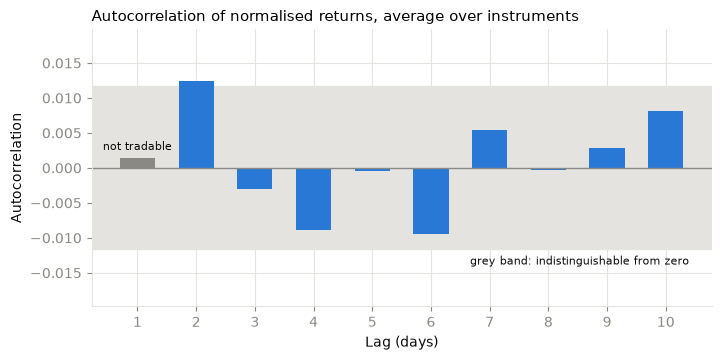

lag,diamonds,butter,cars,cucumber,bananas,average
i64,f64,f64,f64,f64,f64,f64
1,0.02,0.009,-0.012,-0.0,-0.01,0.001
2,0.017,0.027,0.011,0.015,-0.009,0.012
3,-0.005,-0.014,-0.002,0.017,-0.011,-0.003
4,-0.026,0.008,0.001,-0.019,-0.008,-0.009
5,0.013,-0.02,0.002,0.005,-0.002,-0.0
6,0.016,-0.028,-0.022,0.0,-0.013,-0.009
7,0.022,-0.015,-0.005,0.016,0.009,0.005
8,0.003,-0.009,0.011,0.012,-0.018,-0.0
9,-0.012,-0.004,0.014,0.018,-0.0,0.003


In [2]:
VOL_WINDOW = 100
vol = ret.select(DATE, pl.col(instruments).pow(2).rolling_mean(VOL_WINDOW, min_samples=VOL_WINDOW // 2).sqrt())
# each day's return divided by the volatility known the day before
norm_ret = ret.select(DATE, *[(pl.col(c) / vol[c].shift(1)).alias(c) for c in instruments]).drop_nulls()
x = norm_ret.select(instruments).to_numpy()

lags = list(range(1, 11))
autocorr = np.array([[np.corrcoef(x[:-lag, j], x[lag:, j])[0, 1] for j in range(x.shape[1])] for lag in lags])
average_ac = autocorr.mean(axis=1)
noise_band = 2 / np.sqrt(x.size)  # +-2 standard errors if the true autocorrelation is zero

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axhspan(-noise_band, noise_band, color=GRID, zorder=0)
ax.bar(lags, average_ac, width=0.6, color=[MUTED] + [BLUE] * (len(lags) - 1))
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xticks(lags)
ax.set_xlabel("Lag (days)")
ax.set_ylabel("Autocorrelation")
ax.set_title("Autocorrelation of normalised returns, average over instruments")
top = max(noise_band, average_ac.max())
ax.annotate("not tradable", (1, average_ac[0]), xytext=(0, 6), textcoords="offset points",
            ha="center", fontsize=8, color=INK)
ax.annotate("grey band: indistinguishable from zero", (lags[-1] + 0.4, -noise_band), xytext=(0, -11),
            textcoords="offset points", ha="right", fontsize=8, color=INK)
ax.set_ylim(-1.6 * top, 1.6 * top)
plt.show()

pl.DataFrame({"lag": lags, **{c: autocorr[:, j] for j, c in enumerate(instruments)}, "average": average_ac}).with_columns(
    pl.exclude("lag").round(3)
)

**Variance ratio.** If returns were independent, the variance of a $q$-day return would be exactly $q$ times the variance of a daily return, giving a ratio of 1. A ratio **below 1** means moves partly cancel out over that horizon (mean reversion). A ratio **above 1** means they build on each other (trend).

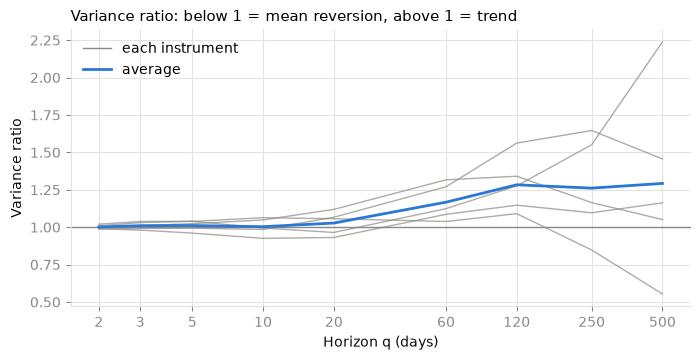

horizon,diamonds,butter,cars,cucumber,bananas,average
i64,f64,f64,f64,f64,f64,f64
2,1.02,1.01,0.99,1.0,0.99,1.0
3,1.04,1.03,0.99,1.01,0.98,1.01
5,1.04,1.04,0.99,1.02,0.96,1.01
10,1.06,0.99,0.98,1.05,0.93,1.0
20,1.06,0.96,1.07,1.12,0.93,1.03
60,1.04,1.12,1.27,1.32,1.09,1.17
120,1.09,1.28,1.56,1.34,1.15,1.28
250,0.85,1.55,1.65,1.16,1.1,1.26
500,0.55,2.24,1.46,1.05,1.16,1.29


In [3]:
def variance_ratio(x: np.ndarray, q: int) -> np.ndarray:
    cumulative = np.cumsum(x, axis=0)
    return (cumulative[q:] - cumulative[:-q]).var(axis=0) / (q * x.var(axis=0))


horizons = [2, 3, 5, 10, 20, 60, 120, 250, 500]
vr = np.array([variance_ratio(x, q) for q in horizons])

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axhline(1, color=MUTED, linewidth=1)
ax.plot(horizons, vr, color=MUTED, linewidth=1, alpha=0.7)
ax.plot([], [], color=MUTED, linewidth=1, label="each instrument")
ax.plot(horizons, vr.mean(axis=1), color=BLUE, label="average")
ax.set_xscale("log")
ax.set_xticks(horizons, [str(q) for q in horizons])
ax.minorticks_off()
ax.set_xlabel("Horizon q (days)")
ax.set_ylabel("Variance ratio")
ax.set_title("Variance ratio: below 1 = mean reversion, above 1 = trend")
ax.legend(frameon=False)
plt.show()

pl.DataFrame({"horizon": horizons, **{c: vr[:, j] for j, c in enumerate(instruments)}, "average": vr.mean(axis=1)}).with_columns(
    pl.exclude("horizon").round(2)
)

## 2. The strategy

Fade the recent move, instrument by instrument:

1. **Signal.** Measure how far the price has travelled over the last `lookback` days in units of its own volatility (a z-score). Take the opposite side: short after a rise, long after a fall, in proportion to the size of the move.
2. **Clip** the z-score so a single extreme move cannot dominate the book.
3. **Smooth** the signal with an exponential moving average. Reversion signals flip quickly, and every flip costs money, so this trades a little signal freshness for much lower turnover.
4. **Volatility-scale** each instrument (equation 2 in the instructions) and **risk-scale** the whole book (equation 3), exactly as in the Quickstart trend model.

The position on day $t$ only uses returns up to and including day $t$.

In [4]:
def reversion_model(
    ret: pl.DataFrame,
    lookback: int = 5,
    smooth: int = 3,
    clip: float = 3.0,
    vol_window: int = 100,
    risk_window: int = 100,
) -> pl.DataFrame:
    cols = [c for c in ret.columns if c != DATE]
    # daily volatility per instrument
    vol = ret.select(DATE, pl.col(cols).pow(2).rolling_mean(vol_window, min_samples=vol_window // 2).sqrt())
    # z-score of the move over the last `lookback` days
    z = ret.select(DATE, *[(pl.col(c).rolling_sum(lookback) / (vol[c] * lookback**0.5)).alias(c) for c in cols])
    # fade the move, clipped
    signal = z.select(DATE, (-pl.col(cols)).clip(-clip, clip))
    # smooth to cut turnover
    if smooth > 1:
        signal = signal.select(DATE, pl.col(cols).ewm_mean(span=smooth))
    # scale with inverse vol to get pos
    positions = signal.select(DATE, *[(pl.col(c) / vol[c]).alias(c) for c in cols])
    # calculate model risk
    gross = positions.select(DATE, *[(pl.col(c).shift(2) * ret[c]).alias(c) for c in cols])
    risk = gross.filter(~pl.all_horizontal(pl.col(cols).is_null())).select(
        DATE, pl.sum_horizontal(pl.col(cols)).rolling_std(risk_window, min_samples=20).alias("model_risk")
    )
    # adjust with model risk
    aligned = positions.join(risk, on=DATE, how="left", maintain_order="left")
    return aligned.select(DATE, *[(pl.col(c) / pl.col("model_risk")).fill_nan(None).alias(c) for c in cols])


position = reversion_model(ret)

## 3. Evaluation

The dashboard from `evaluation.py`, with the default parameters (`lookback=5`, `smooth=3`).

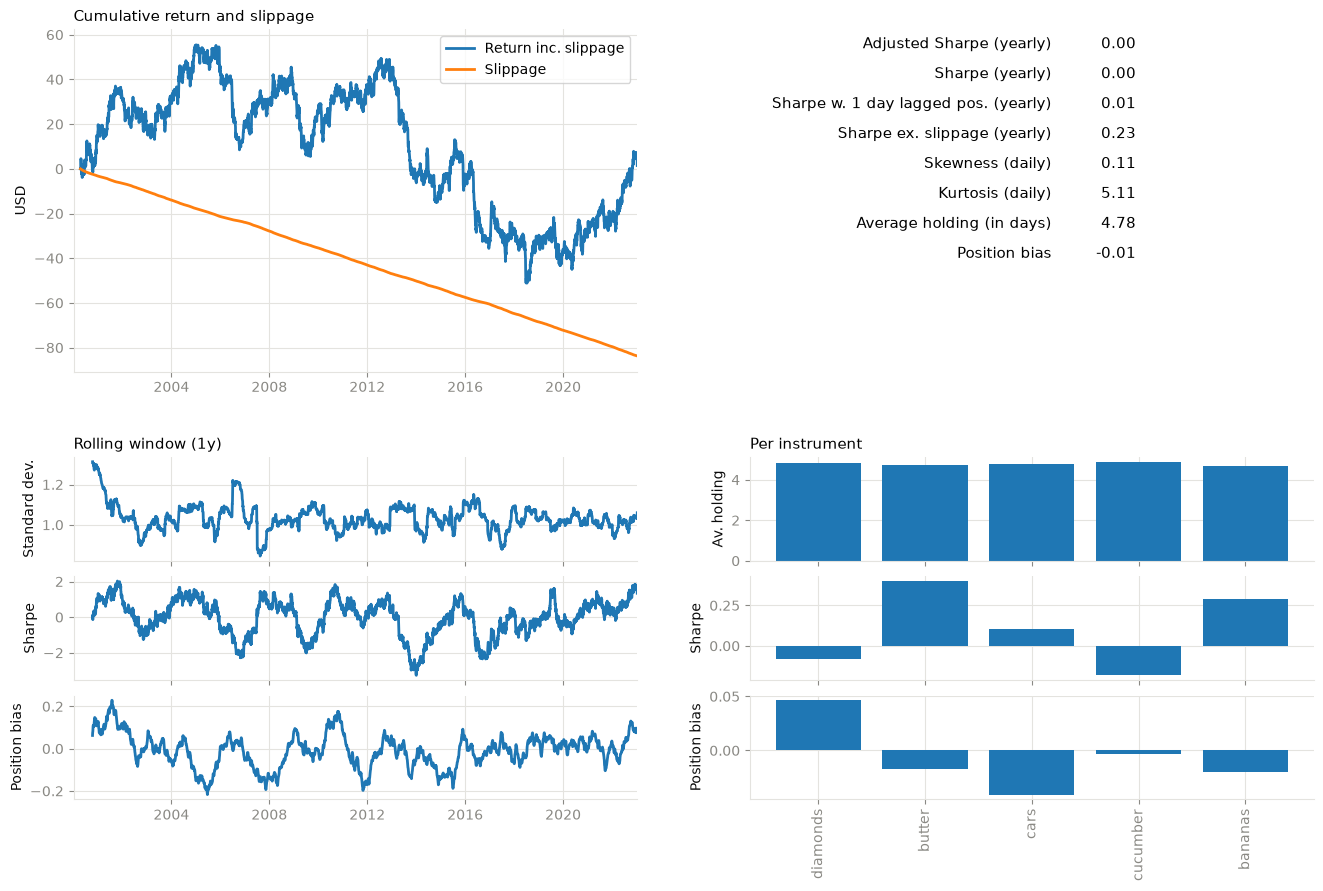

In [5]:
plot_key_figures(position, prices)

In [6]:
KEY_FIGURES = ["adjusted_sharpe", "sharpe", "sharpe_ex_slippage", "sharpe_1d_lag", "av_holding", "skewness", "kurtosis"]


def summary(position: pl.DataFrame, prices: pl.DataFrame = prices, start=None, end=None) -> dict[str, float]:
    if start is not None:
        position = position.filter(pl.col(DATE) >= start)
    if end is not None:
        position = position.filter(pl.col(DATE) < end)
    return calc_key_figures(position, prices, key_figures=KEY_FIGURES)


def table(rows: dict[str, dict[str, float]]) -> pl.DataFrame:
    return pl.DataFrame([{"variant": name, **{k: figures[k] for k in KEY_FIGURES}} for name, figures in rows.items()]).with_columns(
        pl.exclude("variant").round(2)
    )


table({"reversion (lookback=5, smooth=3)": summary(position)})

variant,adjusted_sharpe,sharpe,sharpe_ex_slippage,sharpe_1d_lag,av_holding,skewness,kurtosis
str,f64,f64,f64,f64,f64,f64,f64
"""reversion (lookback=5, smooth=3)""",0.0,0.0,0.23,0.01,4.78,0.11,5.11


### Parameter grid

One good parameter set proves little. The grid shows whether there is a *region* of parameters that works. `sharpe_ex_slippage` is before costs, `adjusted_sharpe` is after costs and is what the competition scores.

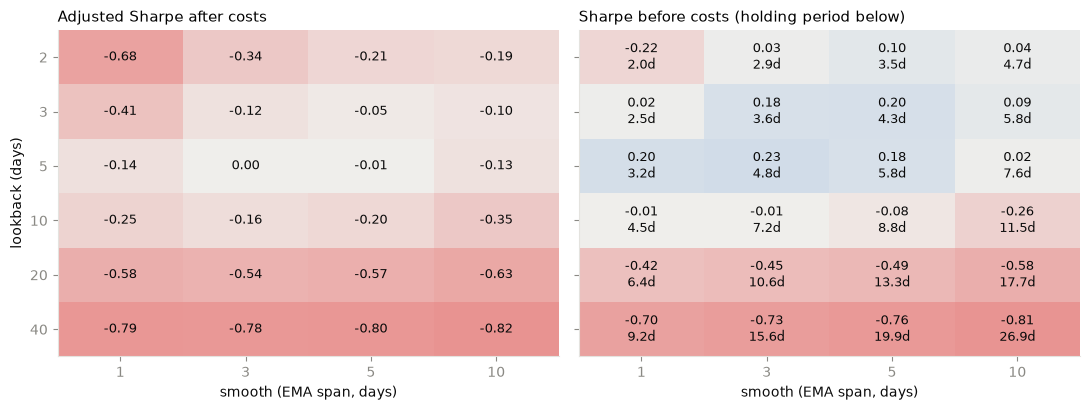

In [7]:
lookbacks = [2, 3, 5, 10, 20, 40]
smooths = [1, 3, 5, 10]
grid = {(lb, sm): summary(reversion_model(ret, lookback=lb, smooth=sm)) for lb in lookbacks for sm in smooths}

diverging = LinearSegmentedColormap.from_list("red_grey_blue", [RED, "#f0efec", BLUE])
panels = [("adjusted_sharpe", "Adjusted Sharpe after costs"), ("sharpe_ex_slippage", "Sharpe before costs (holding period below)")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (figure, title) in zip(axes, panels):
    values = np.array([[grid[lb, sm][figure] for sm in smooths] for lb in lookbacks])
    ax.imshow(values, cmap=diverging, vmin=-1.5, vmax=1.5, aspect="auto")
    for i, lb in enumerate(lookbacks):
        for j, sm in enumerate(smooths):
            label = f"{values[i, j]:.2f}"
            if figure == "sharpe_ex_slippage":
                label += f"\n{grid[lb, sm]['av_holding']:.1f}d"
            ax.text(j, i, label, ha="center", va="center", fontsize=9, color=INK)
    ax.set_xticks(range(len(smooths)), smooths)
    ax.set_yticks(range(len(lookbacks)), lookbacks)
    ax.set_xlabel("smooth (EMA span, days)")
    ax.set_title(title)
    ax.grid(False)
axes[0].set_ylabel("lookback (days)")
fig.tight_layout()
plt.show()

### Sub-periods and instruments

A real effect should show up in both halves of the history and in more than one instrument.

In [8]:
dates = prices[DATE]
middle = dates[len(dates) // 2]
rows = {}
for lb, sm in [(5, 1), (5, 3), (10, 3)]:
    pos = reversion_model(ret, lookback=lb, smooth=sm)
    rows[f"lookback={lb} smooth={sm} | full"] = summary(pos)
    rows[f"lookback={lb} smooth={sm} | first half"] = summary(pos, end=middle)
    rows[f"lookback={lb} smooth={sm} | second half"] = summary(pos, start=middle)
table(rows)

variant,adjusted_sharpe,sharpe,sharpe_ex_slippage,sharpe_1d_lag,av_holding,skewness,kurtosis
str,f64,f64,f64,f64,f64,f64,f64
"""lookback=5 smooth=1 | full""",-0.14,-0.14,0.2,-0.03,3.19,0.17,4.75
"""lookback=5 smooth=1 | first half""",-0.09,-0.09,0.25,0.21,3.19,0.12,4.82
"""lookback=5 smooth=1 | second half""",-0.18,-0.18,0.16,-0.28,3.19,0.22,4.68
"""lookback=5 smooth=3 | full""",0.0,0.0,0.23,0.01,4.78,0.11,5.11
"""lookback=5 smooth=3 | first half""",0.18,0.18,0.41,0.32,4.78,0.04,5.31
"""lookback=5 smooth=3 | second half""",-0.17,-0.17,0.06,-0.3,4.79,0.18,4.92
"""lookback=10 smooth=3 | full""",-0.16,-0.16,-0.01,-0.16,7.2,-0.05,5.04
"""lookback=10 smooth=3 | first half""",0.14,0.14,0.29,0.21,7.15,-0.07,5.59
"""lookback=10 smooth=3 | second half""",-0.46,-0.46,-0.31,-0.53,7.25,-0.03,4.47


In [9]:
# Sharpe before costs, per instrument. With this much history, +-0.2 is roughly one standard error.
per_instrument = {
    f"lookback={lb}": calc_key_figures(reversion_model(ret, lookback=lb, smooth=1), prices, key_figures=["sharpe_per_instrument"])["sharpe_per_instrument"]
    for lb in lookbacks
}
years = prices.height / 260
print(f"one standard error of a Sharpe ratio over {years:.0f} years: {1 / np.sqrt(years):.2f}")
pl.DataFrame([{"variant": name, **values} for name, values in per_instrument.items()]).with_columns(pl.exclude("variant").round(2))

one standard error of a Sharpe ratio over 23 years: 0.21


variant,diamonds,butter,cars,cucumber,bananas
str,f64,f64,f64,f64,f64
"""lookback=2""",-0.13,-0.1,-0.1,-0.35,0.18
"""lookback=3""",0.15,-0.16,-0.1,-0.09,0.25
"""lookback=5""",-0.04,0.22,0.08,-0.13,0.33
"""lookback=10""",-0.07,0.42,-0.22,-0.42,0.28
"""lookback=20""",-0.02,0.12,-0.44,-0.52,-0.07
"""lookback=40""",0.02,-0.23,-0.61,-0.47,-0.25


## 4. Compared with trend

The trend model below is the one from the Quickstart. Both models are scaled to the same risk, so they can be added: `trend + w * reversion` puts a risk weight of `w` on reversion.

In [10]:
def trend_model_vectorized_risk_adjusted(
    ret: pl.DataFrame, trend_window: int = 50, vol_window: int = 100, risk_window: int = 100
) -> pl.DataFrame:
    cols = [c for c in ret.columns if c != DATE]
    vol = ret.select(DATE, pl.col(cols).pow(2).rolling_sum(vol_window, min_samples=vol_window // 2).sqrt())
    signal = ret.select(DATE, pl.col(cols).rolling_sum(trend_window).sign())
    positions = signal.select(DATE, *[(pl.col(c) / vol[c]).alias(c) for c in cols])
    gross = positions.select(DATE, *[(pl.col(c).shift(2) * ret[c]).alias(c) for c in cols])
    risk = gross.filter(~pl.all_horizontal(pl.col(cols).is_null())).select(
        DATE, pl.sum_horizontal(pl.col(cols)).rolling_std(risk_window, min_samples=20).alias("model_risk")
    )
    aligned = positions.join(risk, on=DATE, how="left", maintain_order="left")
    return aligned.select(DATE, *[(pl.col(c) / pl.col("model_risk")).fill_nan(None).alias(c) for c in cols])


def combine(a: pl.DataFrame, b: pl.DataFrame, weight: float) -> pl.DataFrame:
    return a.select(DATE, *[(pl.col(c) + weight * b[c]).alias(c) for c in instruments])


trend = trend_model_vectorized_risk_adjusted(ret)
rows = {"trend": summary(trend), "reversion": summary(position)}
for weight in [0.25, 0.5, 1.0]:
    rows[f"trend + {weight} * reversion"] = summary(combine(trend, position, weight))

daily = lambda pos: calc_key_figures(pos, prices, key_figures=["returns"])["returns"]
both = daily(trend).join(daily(position), on=DATE, suffix="_reversion").drop_nulls()
print(f"correlation of daily returns, trend vs reversion: {both.select(pl.corr('returns', 'returns_reversion')).item():.2f}")
table(rows)

correlation of daily returns, trend vs reversion: -0.31


variant,adjusted_sharpe,sharpe,sharpe_ex_slippage,sharpe_1d_lag,av_holding,skewness,kurtosis
str,f64,f64,f64,f64,f64,f64,f64
"""trend""",0.66,0.66,0.76,0.61,14.86,0.05,3.28
"""reversion""",0.0,0.0,0.23,0.01,4.78,0.11,5.11
"""trend + 0.25 * reversion""",0.71,0.71,0.86,0.66,9.35,0.07,3.43
"""trend + 0.5 * reversion""",0.7,0.7,0.9,0.65,6.41,0.12,3.81
"""trend + 1.0 * reversion""",0.59,0.59,0.83,0.55,4.56,0.19,4.47


## 5. Does the code find reversion when it exists?

A negative result is only informative if the strategy would have caught the effect. Here the same function runs on synthetic prices built as a random walk plus a temporary deviation that decays with a 10-day half-life, so they are mean-reverting by construction.

In [11]:
def synthetic_reverting_prices(half_life: float, n_instruments: int = 5, amplitude: float = 3.0, seed: int = 0) -> pl.DataFrame:
    rng = np.random.default_rng(seed)
    n_days = prices.height
    decay = 0.5 ** (1 / half_life)
    shocks = rng.standard_normal((n_days, n_instruments)) * amplitude * np.sqrt(1 - decay**2)
    deviation = np.zeros((n_days, n_instruments))
    for t in range(1, n_days):
        deviation[t] = decay * deviation[t - 1] + shocks[t]
    random_walk = np.cumsum(rng.standard_normal((n_days, n_instruments)), axis=0)
    names = [f"synthetic_{i}" for i in range(n_instruments)]
    return pl.DataFrame(1000 + random_walk + deviation, schema=names).select(prices[DATE], *names)


synthetic = synthetic_reverting_prices(half_life=10)
synthetic_ret = synthetic.select(DATE, pl.exclude(DATE).diff())
s = synthetic_ret.drop_nulls().select(pl.exclude(DATE)).to_numpy()
print("synthetic autocorrelation at lags 2-5:", np.round([np.mean([np.corrcoef(s[:-lag, j], s[lag:, j])[0, 1] for j in range(s.shape[1])]) for lag in range(2, 6)], 3))
table({f"synthetic, lookback={lb}": summary(reversion_model(synthetic_ret, lookback=lb), synthetic) for lb in [5, 10, 20]})

synthetic autocorrelation at lags 2-5: [-0.016 -0.007 -0.008 -0.014]


variant,adjusted_sharpe,sharpe,sharpe_ex_slippage,sharpe_1d_lag,av_holding,skewness,kurtosis
str,f64,f64,f64,f64,f64,f64,f64
"""synthetic, lookback=5""",0.82,0.85,1.09,0.85,4.55,0.06,4.39
"""synthetic, lookback=10""",1.04,1.1,1.26,0.96,6.62,0.06,4.29
"""synthetic, lookback=20""",1.09,1.19,1.31,1.15,9.28,0.05,4.6


## 6. Look-ahead test

Positions computed from a shorter history must be identical to those computed from the full history.

In [12]:
pos_full = reversion_model(ret)
pos_short = reversion_model(ret.head(ret.height - 250))
comparison = pos_short.join(pos_full, on=DATE, suffix="_full", maintain_order="left")
comparison.select(*[(pl.col(c) - pl.col(f"{c}_full")).abs().sum().alias(c) for c in instruments])

diamonds,butter,cars,cucumber,bananas
f64,f64,f64,f64,f64
0.0,0.0,0.0,0.0,0.0


## 7. Long-horizon reversion, skipping the trend window

The strategy above looks back at most 40 days. The variance ratios in section 1 hint at something slower: some instruments drop below 1 at horizons of 250 days and more. This section tests reversion at that scale.

**Autocorrelation in 50-lag blocks.** Each cell is the sum of the autocorrelations over 50 consecutive lags. Positive blocks at short lags are the trend. Negative blocks further out mean that moves made several months ago tend to be undone later.

In [13]:
import pandas as pd

prices_pd = prices.to_pandas().set_index(DATE)
ret_pd = prices_pd.diff()
vol_pd = np.sqrt((ret_pd**2).rolling(VOL_WINDOW, min_periods=VOL_WINDOW // 2).mean())
norm_r = ret_pd / vol_pd.shift(1)
clean = norm_r.dropna()

blocks = [(a, a + 49) for a in range(1, 400, 50)]
block_ac = pd.DataFrame(
    {c: [sum(clean[c].autocorr(lag) for lag in range(a, b + 1)) for a, b in blocks] for c in instruments},
    index=[f"lag {a}-{b}" for a, b in blocks],
)
print(f"standard error of one block if returns are independent: {np.sqrt(50 / len(clean)):.2f}")
block_ac.round(3)

standard error of one block if returns are independent: 0.09


,diamonds,butter,cars,cucumber,bananas
lag 1-50,0.040,0.136,0.216,0.219,0.091
lag 51-100,-0.014,0.078,0.259,-0.064,0.010
lag 101-150,-0.084,0.076,-0.117,-0.060,-0.165
lag 151-200,-0.192,0.180,0.030,-0.108,0.054
lag 201-250,-0.141,0.050,-0.227,0.150,-0.028
lag 251-300,-0.070,0.276,-0.024,-0.093,0.110
lag 301-350,0.090,0.015,0.026,0.029,0.084
lag 351-400,0.066,0.116,-0.073,0.010,-0.029


**Signal.** Fade the move made between `long` and `skip` days ago, and ignore the most recent `skip` days, which belong to the trend. A 10-day EMA removes the jumps when a large return enters or leaves the window, and the result is divided by its own trailing standard deviation to put it on a z-score scale.

**Gate.** The reversal should only be traded where the instrument has actually behaved that way. If moves made 100 to 300 days ago tend to be undone, the 300-day variance ratio is lower than the 100-day one. The gap between the two is estimated on all history up to each day, and the signal is scaled by it (0 when the gap is negative, capped at 2).

In [14]:
def long_term_reversal(norm_r: pd.DataFrame, skip: int = 80, long: int = 300, span: int = 10) -> pd.DataFrame:
    recent = norm_r.rolling(skip, min_periods=min(30, skip)).sum() if skip > 0 else 0.0
    box = -(norm_r.rolling(long, min_periods=min(100, long)).sum() - recent).ewm(span=span).mean()
    return box / box.rolling(250, min_periods=50).std()


def variance_ratio_gap(norm_r: pd.DataFrame) -> pd.DataFrame:
    daily_var = norm_r.expanding(500).var()
    vr_100 = norm_r.rolling(100).sum().expanding(500).var() / (100.0 * daily_var)
    vr_300 = norm_r.rolling(300).sum().expanding(500).var() / (300.0 * daily_var)
    return vr_100 - vr_300


def annual_sharpe(pnl: pd.DataFrame) -> pd.Series:
    return pnl.mean() / pnl.std() * np.sqrt(260)


def reversal_sharpe(norm_r: pd.DataFrame, skip: int, long: int) -> pd.Series:
    # Sharpe before costs per instrument; the signal of day t earns the return of day t+2
    return annual_sharpe(long_term_reversal(norm_r, skip, long).shift(2) * norm_r)


z_lt = long_term_reversal(norm_r)
pnl = z_lt.shift(2) * norm_r
days = pnl.dropna(how="all").index
cuts = [days[0], days[len(days) // 3], days[2 * len(days) // 3], days[-1]]
by_period = {"full history": annual_sharpe(pnl)}
for a, b in zip(cuts[:-1], cuts[1:]):
    by_period[f"{a.year}-{b.year}"] = annual_sharpe(pnl.loc[a:b])
pd.DataFrame(by_period).T.round(2)

,diamonds,butter,cars,cucumber,bananas
full history,0.53,-0.58,0.20,0.24,0.19
2000-2008,1.13,0.47,-0.16,0.11,0.53
2008-2015,0.61,-0.76,0.38,0.14,0.07
2015-2023,0.13,-1.12,0.48,0.49,-0.04


**Sensitivity to the window.** Sharpe before costs for each instrument over a range of `skip` and `long`. The row `skip = 0` is a plain long-horizon reversal that does not step around the trend.

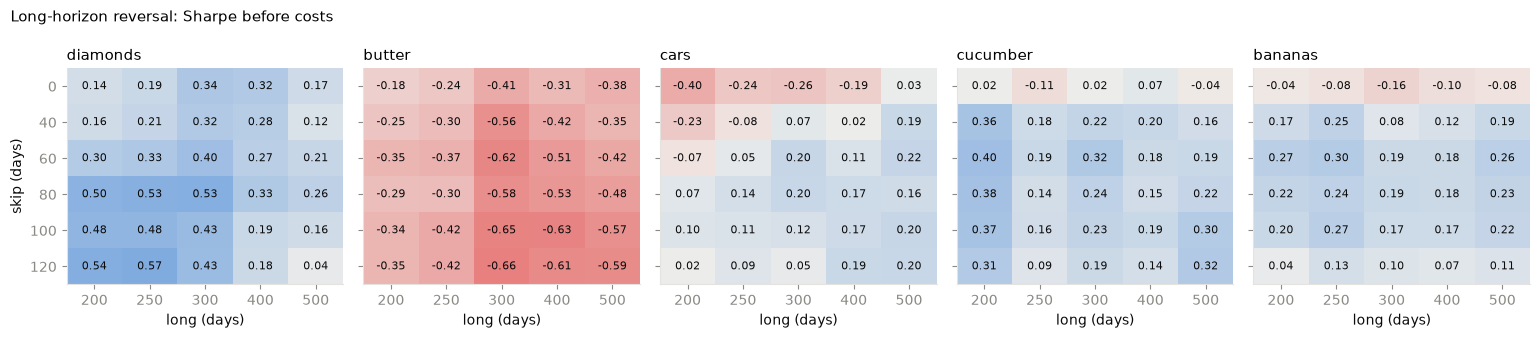

In [15]:
skips = [0, 40, 60, 80, 100, 120]
longs = [200, 250, 300, 400, 500]
surface = {(s, L): reversal_sharpe(norm_r, s, L) for s in skips for L in longs}

n_cols = min(5, len(instruments))
n_rows = -(-len(instruments) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.1 * n_cols, 3.4 * n_rows), sharey=True, squeeze=False)
for ax in axes.ravel()[len(instruments):]:
    ax.axis("off")
for ax, c in zip(axes.ravel(), instruments):
    values = np.array([[surface[s, L][c] for L in longs] for s in skips])
    ax.imshow(values, cmap=diverging, vmin=-1, vmax=1, aspect="auto")
    for i in range(len(skips)):
        for j in range(len(longs)):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center", fontsize=8, color=INK)
    ax.set_xticks(range(len(longs)), longs)
    ax.set_yticks(range(len(skips)), skips)
    ax.set_xlabel("long (days)")
    ax.set_title(c)
    ax.grid(False)
for row in axes:
    row[0].set_ylabel("skip (days)")
fig.suptitle("Long-horizon reversal: Sharpe before costs", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

**How much of this could be luck?** The window was chosen after looking at the autocorrelation table, and the best instrument is picked after the fact. To see what that kind of search finds in data with no structure at all, each instrument's returns are shuffled in time, which destroys every pattern, and the same search is run on the shuffled data. Repeating this 400 times gives the distribution of the best result a search would find by chance. The cell takes about a minute.

In [16]:
N_SETS = 400
rng = np.random.default_rng(0)
values = clean.to_numpy()
n_inst = values.shape[1]
shuffled = pd.DataFrame(np.column_stack([rng.permutation(values[:, j]) for _ in range(N_SETS) for j in range(n_inst)]))

windows = list(surface)
# null[w, s, i]: Sharpe for window w, shuffled data set s, instrument i
null = np.stack([reversal_sharpe(shuffled, s, L).to_numpy().reshape(N_SETS, n_inst) for s, L in windows])
at_window = null[windows.index((80, 300))]

observed = surface[80, 300]
best = observed.idxmax()
best_anywhere = max(surface[w].max() for w in windows)
null_best_anywhere = null.max(axis=(0, 2))

print(f"best instrument at skip=80, long=300: {best}, Sharpe {observed[best]:.2f}")
print(f"standard error of that Sharpe on shuffled data: {at_window.std():.2f}")
print(f"chance of {observed[best]:.2f} or more ...")
print(f"  on one instrument named in advance, window fixed in advance:  {(at_window >= observed[best]).mean():.3f}")
print(f"  on the best of {n_inst} instruments, window fixed in advance:           {(at_window.max(axis=1) >= observed[best]).mean():.3f}")
print(f"best Sharpe over all instruments and all {len(windows)} windows: {best_anywhere:.2f}")
print(f"  the same search on shuffled data finds a median of {np.median(null_best_anywhere):.2f}; chance of {best_anywhere:.2f} or more: {(null_best_anywhere >= best_anywhere).mean():.3f}")

best instrument at skip=80, long=300: diamonds, Sharpe 0.53
standard error of that Sharpe on shuffled data: 0.20
chance of 0.53 or more ...
  on one instrument named in advance, window fixed in advance:  0.006
  on the best of 5 instruments, window fixed in advance:           0.033
best Sharpe over all instruments and all 30 windows: 0.57
  the same search on shuffled data finds a median of 0.48; chance of 0.57 or more: 0.228


**What the gate does.** The table shows the variance-ratio gap through time. For comparison, the same gate is computed on the shuffled data, where there is nothing to detect.

In [17]:
gap = variance_ratio_gap(norm_r)
gate = (gap / 0.25).clip(0, 2).fillna(0.0)
START = gap.dropna().index[0]  # first day on which the gate exists for every instrument

null_gap = variance_ratio_gap(shuffled).dropna()
null_gate = (null_gap / 0.25).clip(0, 2)
print(f"on shuffled data: the gap is positive {(null_gap > 0).to_numpy().mean():.0%} of the time, "
      f"the average gate is {null_gate.to_numpy().mean():.2f}, and {(null_gate.mean() > 1).mean():.0%} of shuffled instruments have an average gate above 1")
print(f"on shuffled data the gap at the end of the history has a standard deviation of {null_gap.iloc[-1].std():.2f}")

yearly = gap.loc[START:].groupby(lambda d: d.year).last()
pd.concat([yearly.iloc[::3].rename(index=lambda y: f"gap at end of {y}"), pd.DataFrame({"average gate (0 to 2)": gate.loc[START:].mean()}).T]).round(2)

on shuffled data: the gap is positive 68% of the time, the average gate is 0.58, and 20% of shuffled instruments have an average gate above 1
on shuffled data the gap at the end of the history has a standard deviation of 0.17


,diamonds,butter,cars,cucumber,bananas
gap at end of 2003,0.59,0.48,0.39,0.61,0.24
gap at end of 2006,0.91,0.01,-0.58,0.82,0.24
gap at end of 2009,0.66,0.15,-0.13,0.00,0.38
gap at end of 2012,0.55,0.15,-0.10,0.22,0.34
gap at end of 2015,0.51,-0.18,-0.18,0.25,0.37
gap at end of 2018,0.45,-0.22,-0.07,0.21,0.14
gap at end of 2021,0.41,-0.44,-0.13,0.22,0.15
average gate (0 to 2),1.91,0.41,0.09,1.05,1.11


**As a strategy, alone and on top of trend.** All variants start on the first day the gate exists, so they are compared over the same period. The trend signal is the one from the Quickstart.

In [18]:
def to_positions(signal: pd.DataFrame, risk_window: int = 100) -> pl.DataFrame:
    # volatility-scale each instrument, then scale the whole book by its trailing risk
    pos = signal / vol_pd
    held = pos.shift(2)
    gross = (held * ret_pd).sum(axis=1, min_count=1)
    gross[held.abs().sum(axis=1) == 0] = np.nan  # days with an empty book say nothing about risk
    risk = gross.rolling(risk_window, min_periods=20).std()
    pos = pos.div(risk, axis=0).loc[START:]
    return pl.from_pandas(pos.reset_index()).with_columns(pl.col(DATE).cast(pl.Date))


trend_signal = np.sign(ret_pd.rolling(50).sum())
lt = z_lt.fillna(0.0)
models = {
    "long-term reversal, all instruments": to_positions(lt),
    "long-term reversal, gated": to_positions(gate * lt),
    "trend": to_positions(trend_signal),
    "trend + 0.25 * long-term reversal, no gate": to_positions(trend_signal + 0.25 * lt),
    "trend + 0.25 * gate * long-term reversal": to_positions(trend_signal + 0.25 * gate * lt),
    "trend + 0.50 * gate * long-term reversal": to_positions(trend_signal + 0.50 * gate * lt),
}
table({name: summary(pos) for name, pos in models.items()})

variant,adjusted_sharpe,sharpe,sharpe_ex_slippage,sharpe_1d_lag,av_holding,skewness,kurtosis
str,f64,f64,f64,f64,f64,f64,f64
"""long-term reversal, all instruments""",0.17,0.17,0.19,0.13,55.63,0.06,3.91
"""long-term reversal, gated""",0.4,0.4,0.43,0.38,46.59,-0.0,5.17
"""trend""",0.69,0.69,0.78,0.66,14.84,0.01,3.23
"""trend + 0.25 * long-term reversal, no gate""",0.7,0.7,0.79,0.68,14.22,0.1,3.63
"""trend + 0.25 * gate * long-term reversal""",0.8,0.81,0.9,0.79,14.63,0.06,3.92
"""trend + 0.50 * gate * long-term reversal""",0.75,0.78,0.86,0.76,15.33,0.11,5.06


**How certain is the improvement?** The daily returns of the two models are resampled together in one-year blocks, and the gain in adjusted Sharpe is recomputed on each resample.

In [19]:
def adjusted_sharpe(r: np.ndarray) -> float:
    s = r.mean() / r.std(ddof=1) * np.sqrt(260)
    r = pd.Series(r)
    return s * (1 + s / 6 * r.skew() - s**2 / 24 * r.kurt())


combined = "trend + 0.25 * gate * long-term reversal"
paired = daily(models["trend"]).join(daily(models[combined]), on=DATE, suffix="_combined").drop_nulls()
paired = paired.select("returns", "returns_combined").to_numpy()

BLOCK, N_BOOT = 250, 2000
rng = np.random.default_rng(1)
n = len(paired)
gains = np.empty(N_BOOT)
for k in range(N_BOOT):
    starts = rng.integers(0, n, -(-n // BLOCK))
    sample = paired[(starts[:, None] + np.arange(BLOCK)).ravel()[:n] % n]
    gains[k] = adjusted_sharpe(sample[:, 1]) - adjusted_sharpe(sample[:, 0])

gain = adjusted_sharpe(paired[:, 1]) - adjusted_sharpe(paired[:, 0])
print(f"gain in adjusted Sharpe from adding the gated reversal: {gain:+.2f}")
print(f"90% of resamples fall between {np.quantile(gains, 0.05):+.2f} and {np.quantile(gains, 0.95):+.2f}; the gain is positive in {(gains > 0).mean():.0%} of them")

gain in adjusted Sharpe from adding the gated reversal: +0.11
90% of resamples fall between -0.09 and +0.29; the gain is positive in 82% of them


In [20]:
# look-ahead test for the gated signal
cut = len(norm_r) - 300
short = norm_r.iloc[:cut]
gated_short = (variance_ratio_gap(short) / 0.25).clip(0, 2).fillna(0.0) * long_term_reversal(short).fillna(0.0)
print("largest difference between positions from the short and the full history:", float((gated_short - (gate * lt).iloc[:cut]).abs().max().max()))

largest difference between positions from the short and the full history: 0.0


## 8. The combined model over time

The model is `trend + 0.25 * gate * long-term reversal`. The plots below show how it behaves through the history, and where the reversal part helps or hurts.

First the standard dashboard from `evaluation.py`.

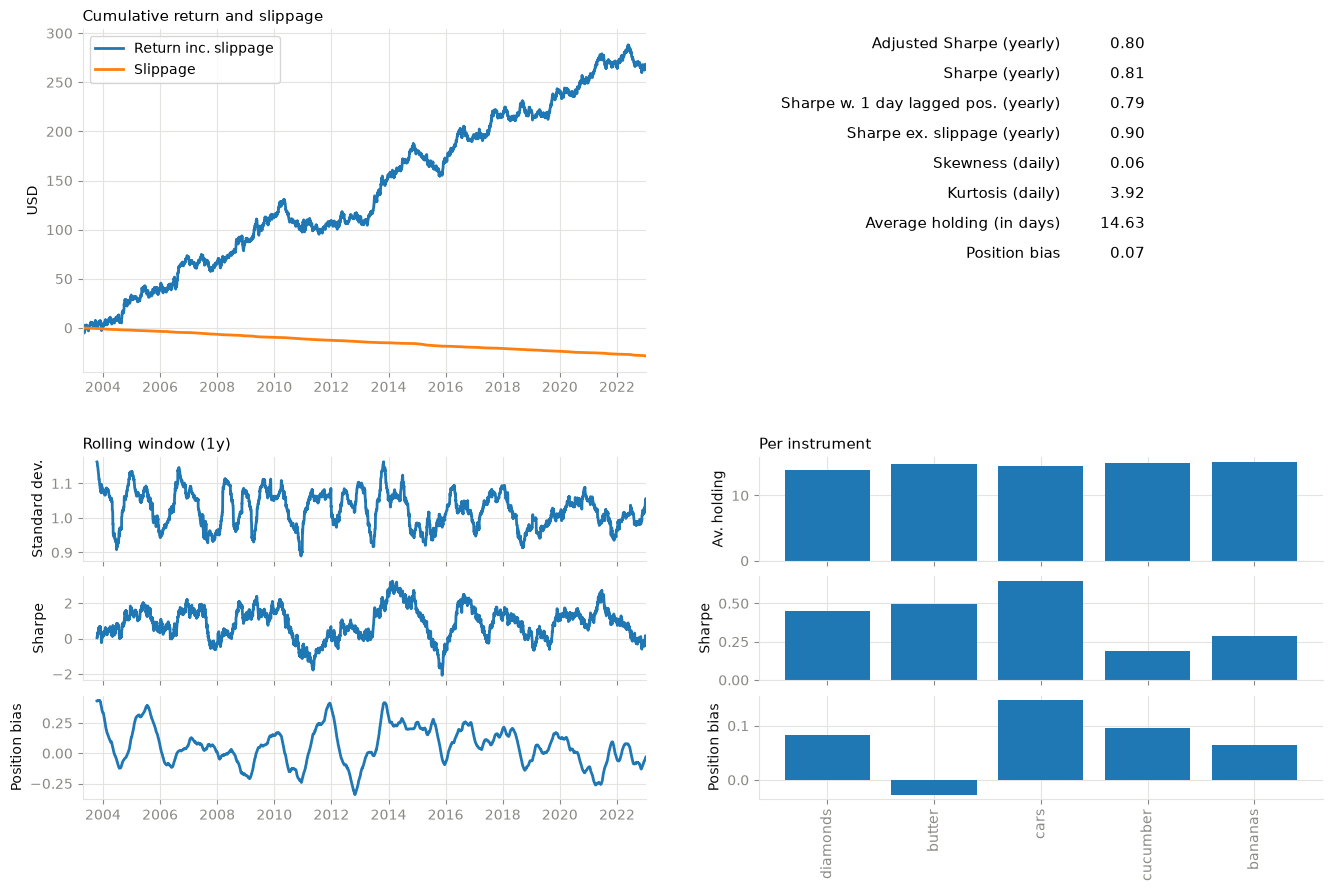

In [21]:
plot_key_figures(models[combined], prices)

**Cumulative return.** Every model is scaled to the same risk, so the curves can be compared directly: a steeper line is a better return for the same risk. The lower panel is the difference between the combined model and trend alone. It rises when the reversal part adds return and falls when it costs.

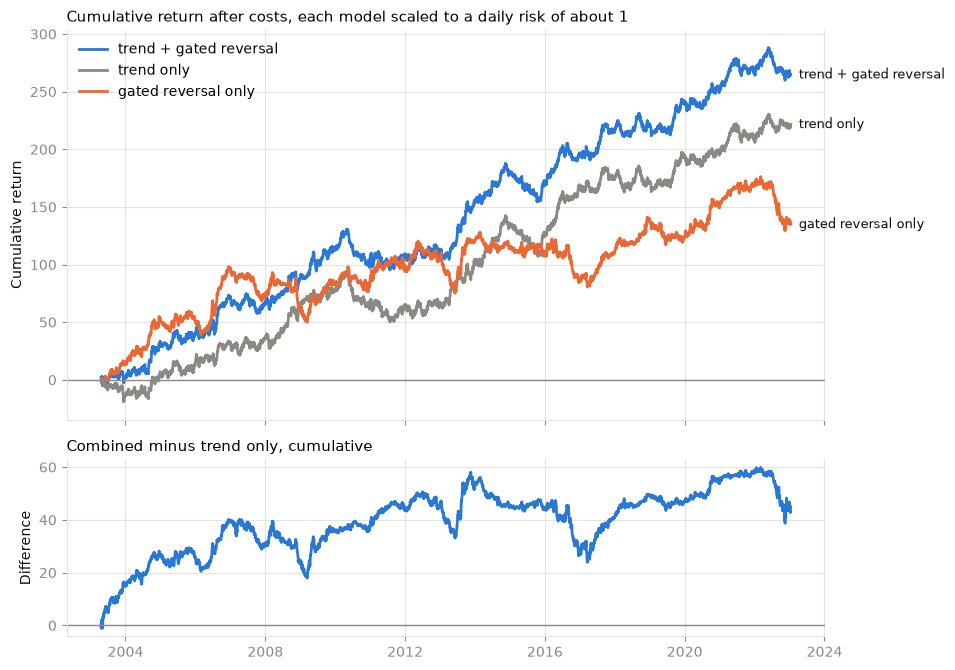

cumulative difference: 38 after the first quarter of the period (2008-03-24), 43 at the end


In [22]:
import matplotlib.dates as mdates

ORANGE = "#eb6834"
curves = {
    "trend + gated reversal": (models[combined], BLUE),
    "trend only": (models["trend"], MUTED),
    "gated reversal only": (models["long-term reversal, gated"], ORANGE),
}

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6.8), sharex=True, height_ratios=[2.2, 1])
for name, (pos, color) in curves.items():
    r = daily(pos).drop_nulls()
    x, y = r[DATE].to_numpy(), r["returns"].cum_sum().to_numpy()
    top.plot(x, y, color=color, label=name)
    top.annotate(name, (x[-1], y[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK, annotation_clip=False)
top.axhline(0, color=MUTED, linewidth=1)
top.set_title("Cumulative return after costs, each model scaled to a daily risk of about 1")
top.set_ylabel("Cumulative return")
top.legend(frameon=False, loc="upper left")

both = daily(models["trend"]).join(daily(models[combined]), on=DATE, suffix="_combined").drop_nulls()
bottom.plot(both[DATE].to_numpy(), (both["returns_combined"] - both["returns"]).cum_sum().to_numpy(), color=BLUE)
bottom.axhline(0, color=MUTED, linewidth=1)
bottom.set_title("Combined minus trend only, cumulative")
bottom.set_ylabel("Difference")
fig.tight_layout()
fig.subplots_adjust(right=0.83)
plt.show()

difference = (both["returns_combined"] - both["returns"]).cum_sum()
quarter = both.height // 4
print(f"cumulative difference: {difference[quarter]:.0f} after the first quarter of the period ({both[DATE][quarter]}), {difference[-1]:.0f} at the end")

**Year by year.** Sharpe after costs for each full calendar year. One year is a short sample, so single bars are noisy. Look at how often the blue bar beats the grey one, and whether the gain is spread out or comes from a few years.

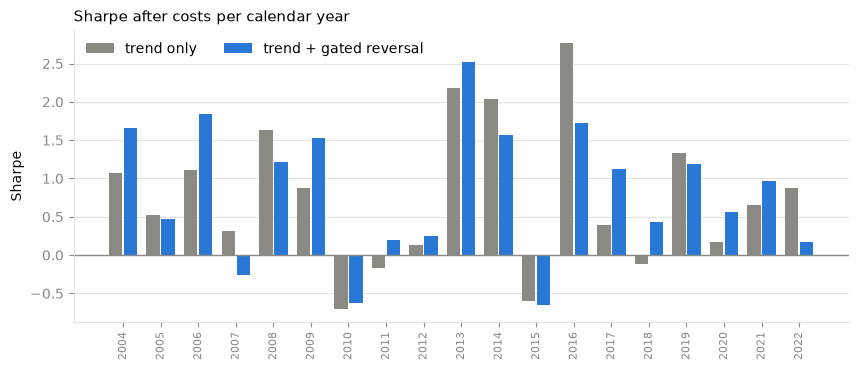

the combined model beats trend only in 11 of 19 full years


In [23]:
def year_sharpe(column: str) -> pl.Expr:
    return (pl.col(column).mean() / pl.col(column).std() * 260**0.5).alias(column)


by_year = (
    both.with_columns(pl.col(DATE).dt.year().alias("year"))
    .group_by("year", maintain_order=True)
    .agg(pl.len().alias("days"), year_sharpe("returns"), year_sharpe("returns_combined"))
    .filter(pl.col("days") >= 200)
)
years = by_year["year"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(years - 0.2, by_year["returns"].to_numpy(), width=0.36, color=MUTED, label="trend only")
ax.bar(years + 0.2, by_year["returns_combined"].to_numpy(), width=0.36, color=BLUE, label="trend + gated reversal")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xticks(years, [str(y) for y in years], rotation=90, fontsize=8)
ax.set_ylabel("Sharpe")
ax.set_title("Sharpe after costs per calendar year")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncols=2)
plt.show()

better = int((by_year["returns_combined"] > by_year["returns"]).sum())
print(f"the combined model beats trend only in {better} of {by_year.height} full years")

**Per instrument.** The top row is the cumulative return of the long-term reversal signal on its own, before costs, with and without the gate. The bottom row is the gate. A flat blue line with a gate at zero means the gate has switched the instrument off.

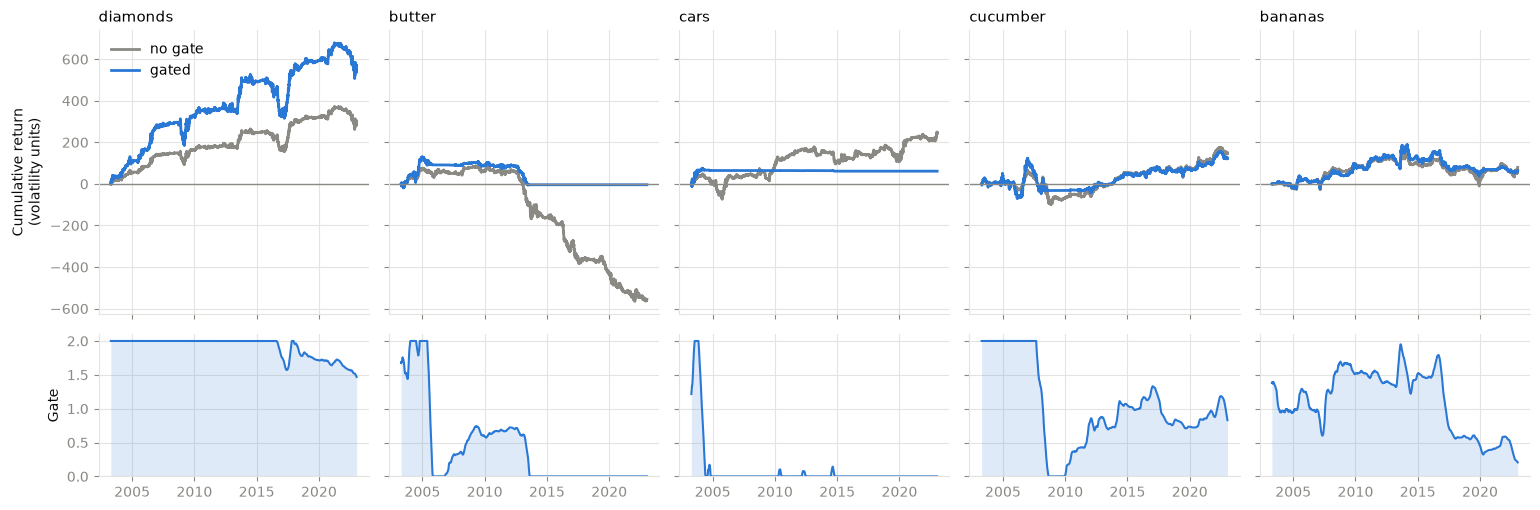

In [24]:
plain = (lt.shift(2) * norm_r).loc[START:].cumsum()
gated = ((gate * lt).shift(2) * norm_r).loc[START:].cumsum()
gate_shown = gate.loc[START:]

for chunk in [instruments[i:i + 5] for i in range(0, len(instruments), 5)]:
    fig, axes = plt.subplots(2, len(chunk), figsize=(3.1 * len(chunk), 5.2), sharex=True, sharey="row", squeeze=False, height_ratios=[2, 1])
    for j, c in enumerate(chunk):
        axes[0, j].plot(plain.index, plain[c], color=MUTED, label="no gate")
        axes[0, j].plot(gated.index, gated[c], color=BLUE, label="gated")
        axes[0, j].axhline(0, color=MUTED, linewidth=1)
        axes[0, j].set_title(c)
        axes[1, j].fill_between(gate_shown.index, gate_shown[c], color=BLUE, alpha=0.15, linewidth=0)
        axes[1, j].plot(gate_shown.index, gate_shown[c], color=BLUE, linewidth=1.5)
        axes[1, j].set_ylim(0, 2.1)
        axes[1, j].xaxis.set_major_locator(mdates.YearLocator(5))
        axes[1, j].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axes[0, 0].set_ylabel("Cumulative return\n(volatility units)")
    axes[1, 0].set_ylabel("Gate")
    axes[0, 0].legend(frameon=False, loc="upper left")
    fig.tight_layout()
    plt.show()

**Anatomy of the position on one instrument.** The last three years for the instrument where the reversal works best. The shaded bands in the price panel show what each signal looks at on the final day: the trend looks at the last 50 days, the reversal at the stretch from 300 to 80 days back. The middle panel shows the two parts of the signal and their sum, and the bottom panel the position that results after volatility and risk scaling.

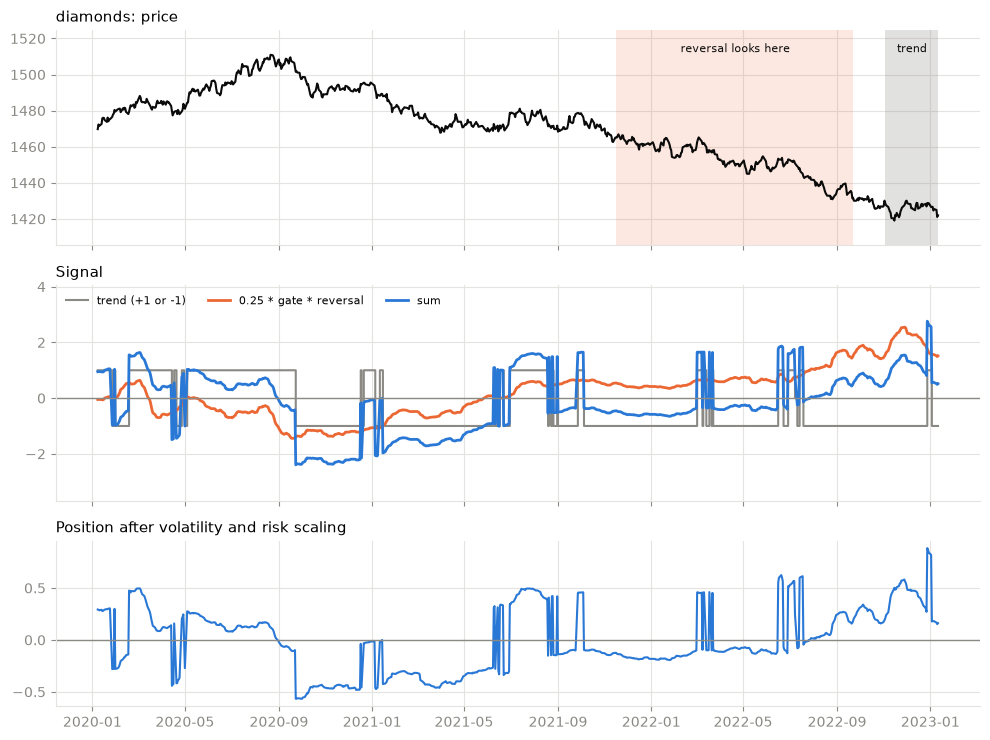

In [25]:
focus = best
window = norm_r.index[-780:]
last_days = norm_r.index

fig, (a, b, c) = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True, height_ratios=[1.3, 1.3, 1])
a.plot(window, prices_pd.loc[window, focus], color=INK, linewidth=1.5)
a.axvspan(last_days[-300], last_days[-80], color=ORANGE, alpha=0.15, linewidth=0)
a.axvspan(last_days[-50], last_days[-1], color=MUTED, alpha=0.25, linewidth=0)
y_top = prices_pd.loc[window, focus].max()
a.annotate("reversal looks here", (last_days[-190], y_top), ha="center", va="bottom", fontsize=8, color=INK)
a.annotate("trend", (last_days[-25], y_top), ha="center", va="bottom", fontsize=8, color=INK)
a.set_title(f"{focus}: price")
a.margins(y=0.15)

trend_part = trend_signal.loc[window, focus]
tilt = (0.25 * gate * lt).loc[window, focus]
b.plot(window, trend_part, color=MUTED, linewidth=1.5, drawstyle="steps-post", label="trend (+1 or -1)")
b.plot(window, tilt, color=ORANGE, label="0.25 * gate * reversal")
b.plot(window, trend_part + tilt, color=BLUE, label="sum")
b.axhline(0, color=MUTED, linewidth=1)
b.set_title("Signal")
b.legend(frameon=False, ncols=3, loc="upper left", fontsize=8)
b.margins(y=0.25)

position_pd = models[combined].to_pandas().set_index(DATE)[focus]
c.plot(position_pd.loc[window[0]:].index, position_pd.loc[window[0]:], color=BLUE, linewidth=1.5)
c.axhline(0, color=MUTED, linewidth=1)
c.set_title("Position after volatility and risk scaling")
fig.tight_layout()
plt.show()

**A note on the scale of the reversal signal.** The last line of `long_term_reversal` divides the signal by its trailing standard deviation, which is measured around the signal's own trailing average. When the signal has sat at one level for a long time that standard deviation is small, so the result can be far larger than a true z-score. In the middle panel above, the reversal part is at times larger than the trend's ±1, so its effective weight is higher than 0.25 suggests. The table checks that the result does not depend on this, by clipping the signal and by using a fixed scale instead.

In [26]:
tilt_all = (0.25 * gate * lt).loc[START:]
print(f"largest value of the reversal signal: {lt.loc[START:].abs().max().max():.1f}")
print(f"{focus}: the reversal part is larger than the trend signal on {(tilt_all[focus].abs() > 1).mean():.0%} of days")

recent = norm_r.rolling(80, min_periods=30).sum()
box = -(norm_r.rolling(300, min_periods=100).sum() - recent).ewm(span=10).mean()
fixed_scale = (box / np.sqrt(300 - 80)).fillna(0.0)  # a 220-day sum of unit-variance returns has a standard deviation of sqrt(220)

table({
    "trend only": summary(models["trend"]),
    "trend + reversal, as written": summary(models[combined]),
    "trend + reversal, signal clipped at +-2": summary(to_positions(trend_signal + 0.25 * gate * lt.clip(-2, 2))),
    "trend + reversal, fixed scale": summary(to_positions(trend_signal + 0.25 * gate * fixed_scale)),
})

largest value of the reversal signal: 9.2
diamonds: the reversal part is larger than the trend signal on 19% of days


variant,adjusted_sharpe,sharpe,sharpe_ex_slippage,sharpe_1d_lag,av_holding,skewness,kurtosis
str,f64,f64,f64,f64,f64,f64,f64
"""trend only""",0.69,0.69,0.78,0.66,14.84,0.01,3.23
"""trend + reversal, as written""",0.8,0.81,0.9,0.79,14.63,0.06,3.92
"""trend + reversal, signal clipped at +-2""",0.78,0.79,0.88,0.77,14.55,0.04,3.69
"""trend + reversal, fixed scale""",0.76,0.77,0.86,0.74,14.78,0.02,3.48


In [27]:
# To submit these positions:
# position.write_csv(NOTEBOOK_DIR / "results_mean_reversion.csv")
# models[combined].write_csv(NOTEBOOK_DIR / "results_trend_plus_reversal.csv")

## Findings on `example_prices.csv`

These are specific to the example data. After switching `PRICES_FILE`, read the outputs above again rather than this section.

**Verdict: short-horizon reversion is not viable on this data. Long-horizon reversion is worth a small weight on top of trend, but the evidence for it is moderate, not strong.**

### Short horizon, up to 40 days (sections 1 to 6)

- **Nothing to fade.** The average autocorrelation at lags 2 to 10 stays inside the noise band (±0.012). The largest value is at lag 2, and it is positive. Variance ratios sit at 1.00 to 1.03 out to 20 days.
- **Break-even at best.** Before costs the Sharpe peaks around 0.2 (lookback 3 to 5), about one standard error from zero. After costs, all 24 parameter sets score an adjusted Sharpe of 0.00 or below.
- **Costs decide it.** Holding for 3 to 5 days loses 0.2 to 0.35 Sharpe to slippage. The trend model holds for 15 days and loses 0.1.
- **Not stable.** The default parameters score +0.18 in the first half of the history and -0.17 in the second.
- **The code is not the problem.** On synthetic prices with a 10-day reversion half-life the same function scores 0.8 to 1.1.

### Long horizon, 80 to 300 days (section 7)

- **There is something there.** For diamonds the autocorrelations over lags 101 to 300 sum to -0.49, which is 2.6 standard errors below zero. Fading the move made 80 to 300 days ago earns a Sharpe of 0.53 before costs on diamonds. Butter is the mirror image (-0.58): it keeps trending at that horizon.
- **Skipping the recent window matters.** With `long = 300`, going from `skip = 0` to `skip = 80` improves four of the five instruments (diamonds from 0.34 to 0.53). The short-horizon strategy in section 2 could not have found this.
- **It is weaker than 0.53 suggests.** If diamonds and the window had been named in advance, a result this good would have a 0.6% chance of being luck. Diamonds was picked as the best of five, which raises that to 3%. The window was also chosen from this data: the same search over 5 instruments and 30 windows on shuffled data typically finds a Sharpe of 0.48, and reaches 0.57 or more in 23% of cases.
- **It fades.** On diamonds the Sharpe is 1.13, 0.61 and 0.13 in successive thirds of the history.
- **The gate is a loose filter.** On shuffled data, where there is nothing to detect, the gap is positive 68% of the time and one instrument in five gets an average gate above 1. Diamonds stands out (1.91). Cucumber (1.05) and bananas (1.11) do not. In this data the gate earns its keep by switching off butter, which it only does after 2012.
- **On top of trend it helps.** Adding the gated signal at a weight of 0.25 lifts the adjusted Sharpe from 0.69 to 0.80. Without the gate it is 0.70, and at a weight of 0.50 it is 0.75. Resampling the history in one-year blocks puts 90% of the gains between -0.09 and +0.29, and the gain is positive in 82% of resamples.
- **The gain came early.** The combined model's lead over trend alone, in units of daily risk, reaches 38 by March 2008, a quarter of the way through the period, and is 43 at the end. It beats trend alone in 11 of 19 full years (section 8).
- **The signal's scale is loose.** The reversal signal is not a true z-score: it reaches 9.2, and on diamonds it outweighs the trend signal on 19% of days, so its effective weight is above 0.25. The result does not depend on this. With the signal clipped at ±2 the adjusted Sharpe is 0.78, and with a fixed scale it is 0.76, against 0.80 as written and 0.69 for trend alone.

The signal is slow (a holding period of about 47 days on its own), so it costs little to carry. A weight of 0.25 is a reasonable size for evidence of this strength. The windows (80, 300) and the gate scale (0.25) were fitted to this data, so re-run section 7 on the real data before reusing them.

### Two things to keep in mind on the real data

- Short-horizon reversion returns are fat-tailed here (kurtosis 5.1, against 3.3 for trend). Ignoring skew, the adjusted Sharpe multiplies the Sharpe by $1 - \frac{SR^2}{24}(\text{kurtosis} - 3)$. At kurtosis 5 that costs 8% at a Sharpe of 1 and 33% at a Sharpe of 2.
- `evaluation.py` charges 0.02 daily standard deviations per unit traded. The instructions quote $\delta = 0.0002$ per unit, which on these prices is roughly 200 times cheaper. Under the cheaper cost the short-horizon strategy nets about 0.2 instead of 0.0. It is worth asking which one is used for scoring, since it sets how fast a strategy can afford to trade.